# Stage 10 — Quarterly Expanding-Window Validation

Replace the single 2021/2022/2023 calendar-year evaluation with eight quarterly expanding-window folds. Each test quarter is predicted by a model that has seen neither that quarter nor any later data. The immediately preceding quarter selects the tree count; a fresh model is then refitted on all permissible pre-test rows.

Fold means and standard deviations measure temporal variability across the eight test quarters. They are not confidence intervals because the expanding folds overlap and are not independent.

## Comparison anchor

Notebook 8b's corrected single-split H+3 R² is approximately 0.811 on the common persistence mask. The walk-forward gap is reported as temporal sensitivity, not used to reject the more demanding evaluation.

## Outputs

- `walk_forward_scores.csv`, `walk_forward_summary.csv`, and `walk_forward_summary_all_targets.csv`
- `walk_forward_persistence.csv` and `walk_forward_training_audit.csv`
- `walk_forward_manifest.json`
- `figs/10_walk_forward.png` and `figs/10_walk_forward_per_fold.png`


## 10.0 — Load v2 sample, define quarterly folds

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score

PROC_DIR = Path("data/processed")
MODEL_DIR = Path("models")
FIG_DIR = Path("figs")
FIG_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_MANIFEST_PATH = PROC_DIR / "feature_manifest_v2.json"
BASE_MANIFEST_PATH = PROC_DIR / "feature_manifest.json"
SAMPLE_PATH = PROC_DIR / "supervised_sample_v2.parquet"
SINGLE_SCORE_PATH = PROC_DIR / "xgb_v2_scores.csv"

for path in (
    FEATURE_MANIFEST_PATH,
    BASE_MANIFEST_PATH,
    SAMPLE_PATH,
    SINGLE_SCORE_PATH,
):
    if not path.exists():
        raise FileNotFoundError(path)

manifest = json.loads(FEATURE_MANIFEST_PATH.read_text())
base_manifest = json.loads(BASE_MANIFEST_PATH.read_text())
FEATURE_COLS = manifest["feature_cols"]
HORIZONS = manifest["horizons"]
LABEL_EXTRA_DAYS = (
    2 if base_manifest.get("use_3day_target", False) else 0
)

df = (
    pd.read_parquet(SAMPLE_PATH)
    .sort_values(["time", "latitude", "longitude"])
    .reset_index(drop=True)
)
df["time"] = pd.to_datetime(df["time"])

if len(df) != 360_000:
    raise RuntimeError(
        f"Expected 360,000 rows; found {len(df):,}"
    )

missing_features = set(FEATURE_COLS) - set(df.columns)
if missing_features:
    raise RuntimeError(
        f"Missing model features: {sorted(missing_features)}"
    )

df["quarter"] = df["time"].dt.to_period("Q")
all_quarters = sorted(df["quarter"].unique())

print(f"Rows       : {len(df):,}")
print(
    f"Time range : {df.time.min().date()} → "
    f"{df.time.max().date()}"
)
print(f"Features   : {len(FEATURE_COLS)}")
print(f"Quarters   : {len(all_quarters)}")
print(f"Label extension: {LABEL_EXTRA_DAYS} days")

for quarter in all_quarters:
    subset = df[df["quarter"] == quarter]
    print(
        f"  {quarter}: {subset.time.min().date()} → "
        f"{subset.time.max().date()} ({len(subset):,} rows)"
    )

Rows       : 360,000
Time range : 2021-01-01 → 2023-12-30
Features   : 32
Quarters   : 12
Label extension: 0 days
  2021Q1: 2021-01-01 → 2021-03-31 (30,000 rows)
  2021Q2: 2021-04-01 → 2021-06-30 (30,000 rows)
  2021Q3: 2021-07-01 → 2021-09-30 (30,000 rows)
  2021Q4: 2021-10-01 → 2021-12-31 (30,000 rows)
  2022Q1: 2022-01-01 → 2022-03-31 (30,000 rows)
  2022Q2: 2022-04-01 → 2022-06-30 (30,000 rows)
  2022Q3: 2022-07-01 → 2022-09-30 (30,000 rows)
  2022Q4: 2022-10-01 → 2022-12-31 (30,000 rows)
  2023Q1: 2023-01-01 → 2023-03-31 (30,000 rows)
  2023Q2: 2023-04-01 → 2023-06-30 (30,000 rows)
  2023Q3: 2023-07-01 → 2023-09-30 (30,000 rows)
  2023Q4: 2023-10-01 → 2023-12-30 (30,000 rows)


## 10.1 — Define the fold structure

**Expanding-window:** training data grows with each fold; test data is always exactly one quarter.

- Start: fit on Q1–Q3 2021, validate on Q4 2021, refit through Q4, then test on Q1 2022.
- Then: fit through Q4 2021, validate on Q1 2022, refit through Q1, then test on Q2 2022.
- …
- End: fit through Q2 2023, validate on Q3 2023, refit through Q3, then test on Q4 2023.

That's 8 folds — at the upper end of PLAN.md's *6-8 walk-forward folds* requirement. Each quarter has 30,000 sampled rows. The pre-validation fit set grows from 90,000 to 300,000 rows, while the final pre-test refit set grows from 120,000 to 330,000 rows before horizon-specific boundary purging.

For early-stopping we use the **last quarter of the training window as validation** (no overlap with the test quarter). Same regularisation discipline as Notebook 8b.

In [2]:
MIN_TRAIN_QUARTERS = 4
FOLDS = []

for index in range(MIN_TRAIN_QUARTERS, len(all_quarters)):
    pretest_quarters = all_quarters[:index]
    validation_quarter = pretest_quarters[-1]
    fitting_quarters = pretest_quarters[:-1]
    test_quarter = all_quarters[index]

    FOLDS.append({
        "fold": index - MIN_TRAIN_QUARTERS + 1,
        "fit_quarters": fitting_quarters,
        "validation_quarter": validation_quarter,
        "test_quarter": test_quarter,
        "fit_end": fitting_quarters[-1].end_time.normalize(),
        "validation_start": validation_quarter.start_time.normalize(),
        "validation_end": validation_quarter.end_time.normalize(),
        "test_start": test_quarter.start_time.normalize(),
        "test_end": test_quarter.end_time.normalize(),
    })

print(f"Fold plan: {len(FOLDS)} folds")
for fold in FOLDS:
    fit_count = int(
        df["quarter"].isin(fold["fit_quarters"]).sum()
    )
    validation_count = int(
        (df["quarter"] == fold["validation_quarter"]).sum()
    )
    test_count = int(
        (df["quarter"] == fold["test_quarter"]).sum()
    )
    print(
        f"  fold {fold['fold']}: "
        f"fit={fold['fit_quarters'][0]}.."
        f"{fold['fit_quarters'][-1]} ({fit_count:,}), "
        f"val={fold['validation_quarter']} ({validation_count:,}), "
        f"test={fold['test_quarter']} ({test_count:,})"
    )

Fold plan: 8 folds
  fold 1: fit=2021Q1..2021Q3 (90,000), val=2021Q4 (30,000), test=2022Q1 (30,000)
  fold 2: fit=2021Q1..2021Q4 (120,000), val=2022Q1 (30,000), test=2022Q2 (30,000)
  fold 3: fit=2021Q1..2022Q1 (150,000), val=2022Q2 (30,000), test=2022Q3 (30,000)
  fold 4: fit=2021Q1..2022Q2 (180,000), val=2022Q3 (30,000), test=2022Q4 (30,000)
  fold 5: fit=2021Q1..2022Q3 (210,000), val=2022Q4 (30,000), test=2023Q1 (30,000)
  fold 6: fit=2021Q1..2022Q4 (240,000), val=2023Q1 (30,000), test=2023Q2 (30,000)
  fold 7: fit=2021Q1..2023Q1 (270,000), val=2023Q2 (30,000), test=2023Q3 (30,000)
  fold 8: fit=2021Q1..2023Q2 (300,000), val=2023Q3 (30,000), test=2023Q4 (30,000)


## 10.2 — Run all folds × horizons

For each fold and horizon: purge issue times whose labels cross a boundary, choose the tree count on the immediately preceding validation quarter, refit with that fixed count on every permissible pre-test row, then score the untouched test quarter. The primary score uses the exact persistence comparison mask; an all-observed-target score is retained separately. This is 112 fits in total.

In [3]:
import time as pytime

COMMON_PARAMS = {
    "max_depth": 6,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "missing": np.nan,
    "eval_metric": "rmse",
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "n_jobs": -1,
    "random_state": 42,
    "verbosity": 0,
}


def score_arrays(y_true, y_pred):
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)),
        "n": int(len(y_true)),
    }


def fit_eval(fit_df, validation_df, test_df, fold, h):
    target_col = f"target_h{h}"
    label_offset = h + LABEL_EXTRA_DAYS
    fit_deadline = fold["fit_end"] - pd.Timedelta(days=label_offset)
    validation_deadline = (
        fold["validation_end"] - pd.Timedelta(days=label_offset)
    )

    fit_h = fit_df[
        (fit_df["time"] <= fit_deadline)
        & fit_df[target_col].notna()
    ]
    validation_h = validation_df[
        (validation_df["time"] <= validation_deadline)
        & validation_df[target_col].notna()
    ]
    reference_df = pd.concat(
        [fit_df, validation_df], ignore_index=True
    )
    reference_h = reference_df[
        (reference_df["time"] <= validation_deadline)
        & reference_df[target_col].notna()
    ]

    if fit_h.empty or validation_h.empty or reference_h.empty:
        raise RuntimeError(
            f"Empty fitting split for fold {fold['fold']} H+{h}"
        )

    tuning_model = xgb.XGBRegressor(
        n_estimators=1200,
        early_stopping_rounds=50,
        **COMMON_PARAMS,
    )
    tuning_model.fit(
        fit_h[FEATURE_COLS],
        fit_h[target_col],
        eval_set=[(
            validation_h[FEATURE_COLS],
            validation_h[target_col],
        )],
        verbose=False,
    )
    best_rounds = int(tuning_model.best_iteration) + 1

    final_model = xgb.XGBRegressor(
        n_estimators=best_rounds, **COMMON_PARAMS
    )
    final_model.fit(
        reference_h[FEATURE_COLS],
        reference_h[target_col],
        verbose=False,
    )

    all_target_mask = test_df[target_col].notna()
    common_mask = (
        all_target_mask & test_df["log_chl_t0"].notna()
    )

    prediction_all = final_model.predict(
        test_df.loc[all_target_mask, FEATURE_COLS]
    )
    prediction_common = final_model.predict(
        test_df.loc[common_mask, FEATURE_COLS]
    )
    all_score = score_arrays(
        test_df.loc[all_target_mask, target_col], prediction_all
    )
    common_score = score_arrays(
        test_df.loc[common_mask, target_col], prediction_common
    )

    return {
        "best_rounds": best_rounds,
        "rmse": common_score["rmse"],
        "r2": common_score["r2"],
        "n": common_score["n"],
        "rmse_all": all_score["rmse"],
        "r2_all": all_score["r2"],
        "n_all": all_score["n"],
        "fit_rows": len(fit_h),
        "validation_rows": len(validation_h),
        "refit_rows": len(reference_h),
        "fit_max_label_time": (
            fit_h["time"].max() + pd.Timedelta(days=label_offset)
        ),
        "validation_max_label_time": (
            validation_h["time"].max()
            + pd.Timedelta(days=label_offset)
        ),
        "refit_max_label_time": (
            reference_h["time"].max()
            + pd.Timedelta(days=label_offset)
        ),
    }


score_rows = []
audit_rows = []

for fold in FOLDS:
    started = pytime.time()
    fit_df = df[df["quarter"].isin(fold["fit_quarters"])]
    validation_df = df[
        df["quarter"] == fold["validation_quarter"]
    ]
    test_df = df[df["quarter"] == fold["test_quarter"]]

    print(
        f"\nFold {fold['fold']} test={fold['test_quarter']} "
        f"fit={len(fit_df):,} val={len(validation_df):,} "
        f"test={len(test_df):,}"
    )

    for h in HORIZONS:
        result = fit_eval(
            fit_df, validation_df, test_df, fold, h
        )
        score_rows.append({
            "fold": fold["fold"],
            "test_quarter": str(fold["test_quarter"]),
            "horizon": h,
            "best_rounds": result["best_rounds"],
            "rmse": result["rmse"],
            "r2": result["r2"],
            "n": result["n"],
            "rmse_all": result["rmse_all"],
            "r2_all": result["r2_all"],
            "n_all": result["n_all"],
        })
        audit_rows.append({
            "fold": fold["fold"],
            "horizon": h,
            "fit_end": fold["fit_end"],
            "validation_start": fold["validation_start"],
            "validation_end": fold["validation_end"],
            "test_start": fold["test_start"],
            "test_end": fold["test_end"],
            "fit_rows": result["fit_rows"],
            "validation_rows": result["validation_rows"],
            "refit_rows": result["refit_rows"],
            "fit_max_label_time": result["fit_max_label_time"],
            "validation_max_label_time": (
                result["validation_max_label_time"]
            ),
            "refit_max_label_time": result["refit_max_label_time"],
        })
        print(
            f"  H+{h}: common RMSE={result['rmse']:.4f} "
            f"R²={result['r2']:.4f} N={result['n']:,}; "
            f"all-target N={result['n_all']:,}; "
            f"rounds={result['best_rounds']}"
        )

    print(
        f"  fold {fold['fold']} took "
        f"{pytime.time() - started:.1f}s"
    )

wf_scores = pd.DataFrame(score_rows)
wf_audit = pd.DataFrame(audit_rows)
print(f"\nCompleted {len(wf_scores)} fold-horizon fits.")


Fold 1 test=2022Q1 fit=90,000 val=30,000 test=30,000
  H+1: common RMSE=0.1372 R²=0.6323 N=8,434; all-target N=14,544; rounds=208
  H+2: common RMSE=0.1593 R²=0.5216 N=6,826; all-target N=14,383; rounds=175
  H+3: common RMSE=0.1645 R²=0.4511 N=6,405; all-target N=14,398; rounds=220
  H+4: common RMSE=0.1877 R²=0.1880 N=6,743; all-target N=14,383; rounds=64
  H+5: common RMSE=0.1737 R²=0.3113 N=6,427; all-target N=14,021; rounds=167
  H+6: common RMSE=0.1820 R²=0.2807 N=6,968; all-target N=14,039; rounds=189
  H+7: common RMSE=0.1837 R²=0.2680 N=7,229; all-target N=14,045; rounds=155
  fold 1 took 19.6s

Fold 2 test=2022Q2 fit=120,000 val=30,000 test=30,000
  H+1: common RMSE=0.0720 R²=0.8127 N=12,972; all-target N=17,646; rounds=162
  H+2: common RMSE=0.0854 R²=0.7172 N=11,588; all-target N=17,296; rounds=224
  H+3: common RMSE=0.0903 R²=0.6824 N=10,633; all-target N=17,376; rounds=197
  H+4: common RMSE=0.0921 R²=0.6109 N=10,188; all-target N=17,383; rounds=178
  H+5: common RMSE=0.

## 10.3 — Aggregate mean ± standard deviation

The primary walk-forward summary uses the common persistence mask in every fold. The operational all-observed-target summary is retained separately. The single-split comparison is read from Notebook 8b's corrected score artifact rather than recomputed on a different window.

In [4]:
summary = (
    wf_scores.groupby("horizon")
    .agg(
        rmse_mean=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        r2_mean=("r2", "mean"),
        r2_std=("r2", "std"),
        n_folds=("r2", "size"),
    )
)

summary_all = (
    wf_scores.groupby("horizon")
    .agg(
        rmse_mean=("rmse_all", "mean"),
        rmse_std=("rmse_all", "std"),
        r2_mean=("r2_all", "mean"),
        r2_std=("r2_all", "std"),
        n_folds=("r2_all", "size"),
    )
)

single_scores = pd.read_csv(SINGLE_SCORE_PATH)
if "evaluation_scope" in single_scores.columns:
    single_scores = single_scores[
        single_scores["evaluation_scope"]
        == "common_persistence_mask"
    ]

single = (
    single_scores[["horizon", "r2", "rmse", "n"]]
    .rename(columns={
        "r2": "single_split_r2",
        "rmse": "single_split_rmse",
        "n": "single_split_n",
    })
    .set_index("horizon")
    .sort_index()
)

compare = summary.join(single)
compare["r2_diff_wf_minus_single"] = (
    compare["r2_mean"] - compare["single_split_r2"]
)

print("Walk-forward common-mask summary:")
print(summary.round(4).to_string())
print("\nOperational all-target summary:")
print(summary_all.round(4).to_string())
print("\nWalk-forward versus corrected single split:")
print(
    compare[[
        "r2_mean",
        "r2_std",
        "single_split_r2",
        "r2_diff_wf_minus_single",
        "n_folds",
    ]].round(4).to_string()
)

Walk-forward common-mask summary:
         rmse_mean  rmse_std  r2_mean  r2_std  n_folds
horizon                                               
1           0.0914    0.0270   0.7745  0.0793        8
2           0.1061    0.0321   0.7020  0.0994        8
3           0.1131    0.0345   0.6541  0.1208        8
4           0.1209    0.0404   0.5819  0.1869        8
5           0.1236    0.0377   0.5569  0.1441        8
6           0.1277    0.0383   0.5309  0.1399        8
7           0.1284    0.0397   0.5355  0.1485        8

Operational all-target summary:
         rmse_mean  rmse_std  r2_mean  r2_std  n_folds
horizon                                               
1           0.0991    0.0276   0.7489  0.0865        8
2           0.1121    0.0302   0.6825  0.0956        8
3           0.1190    0.0335   0.6456  0.1130        8
4           0.1275    0.0393   0.5827  0.1700        8
5           0.1297    0.0367   0.5669  0.1337        8
6           0.1310    0.0359   0.5612  0.1312        

## 10.4 — Plot fold variability and the single-split diagnostic

Show mean R² and RMSE with ±1 fold standard deviation beside the corrected Notebook 8b single-split point. This visualizes temporal variability and the evaluation-window gap; the error bars are descriptive standard deviations, not formal confidence intervals.


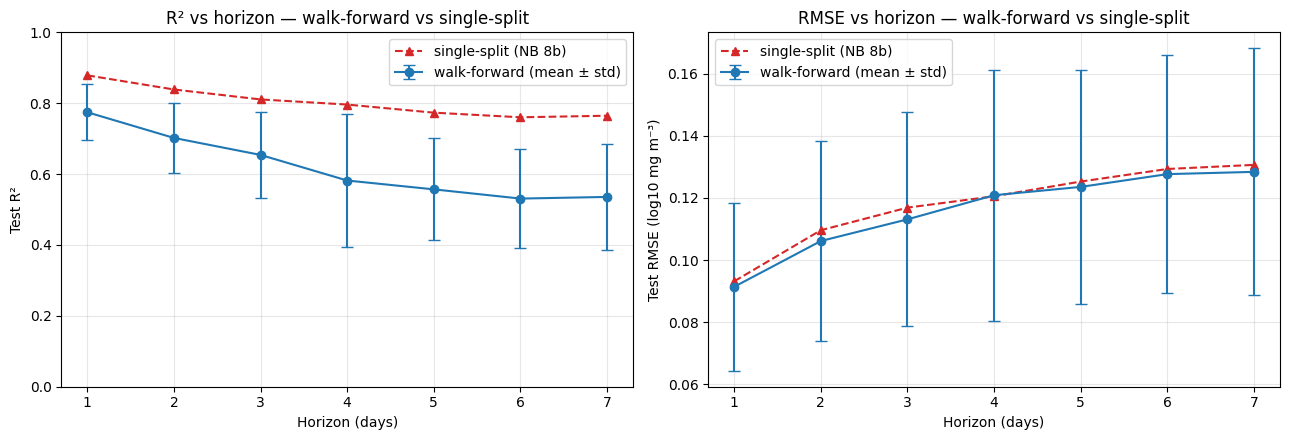

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

h_idx = summary.index.values
axes[0].errorbar(h_idx, summary["r2_mean"], yerr=summary["r2_std"],
                 fmt="o-", color="#1f77b4", capsize=4, label="walk-forward (mean ± std)")
axes[0].plot(h_idx, compare["single_split_r2"], "^--", color="#d62728",
             label="single-split (NB 8b)")
axes[0].set_xlabel("Horizon (days)"); axes[0].set_ylabel("Test R²")
axes[0].set_title("R² vs horizon — walk-forward vs single-split")
axes[0].legend(); axes[0].grid(alpha=0.3); axes[0].set_ylim(0, 1)

axes[1].errorbar(h_idx, summary["rmse_mean"], yerr=summary["rmse_std"],
                 fmt="o-", color="#1f77b4", capsize=4, label="walk-forward (mean ± std)")
axes[1].plot(h_idx, compare["single_split_rmse"], "^--", color="#d62728",
             label="single-split (NB 8b)")
axes[1].set_xlabel("Horizon (days)"); axes[1].set_ylabel("Test RMSE (log10 mg m⁻³)")
axes[1].set_title("RMSE vs horizon — walk-forward vs single-split")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "10_walk_forward.png", dpi=150)
plt.show()

### Per-fold breakdown (which quarter is hardest?)

A second view: R² vs test quarter for each horizon. This is where you spot whether a specific quarter (e.g. winter blooms) is consistently the hardest to forecast.

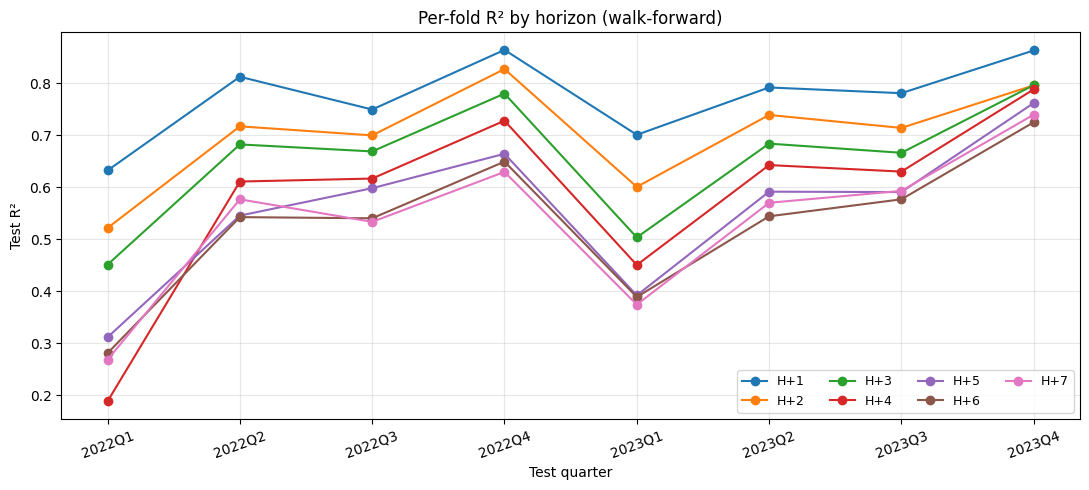

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
for h in HORIZONS:
    sub = wf_scores[wf_scores.horizon == h].sort_values("fold")
    ax.plot(sub["test_quarter"], sub["r2"], marker="o", label=f"H+{h}")
ax.set_xlabel("Test quarter"); ax.set_ylabel("Test R²")
ax.set_title("Per-fold R² by horizon (walk-forward)")
ax.legend(ncol=4, fontsize=9); ax.grid(alpha=0.3)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(FIG_DIR / "10_walk_forward_per_fold.png", dpi=150)
plt.show()

---
## Validation Gate 10

The gate requires 56 fold-horizon results—eight folds at every horizon—plus matched model/persistence row counts and broader all-target coverage. It audits ordered fold periods and ensures fitted, validation, and refit labels never cross their boundaries. It also requires maximum fold-to-fold R² standard deviation below 0.20, mean model improvement over matched persistence at every horizon, overall weakening from H+1 to H+7, and both figures.

The single-split gap is reported but not gated. The quarterly mean and standard deviation are the primary temporal-validation summary.


## 10.5 — Walk-forward persistence baseline (per-fold)

The persistence numbers from Notebook 5 were scored on a **single-split** test window. Comparing them directly with an eight-quarter walk-forward mean would mix evaluation windows.

The right comparison is **walk-forward persistence**: for each fold, persistence_pred = `log_chl_t0` on the same test quarter the model was scored on. Mean ± std across folds gives a directly-comparable bar.

In [7]:
pers_rows = []

for fold in FOLDS:
    test_df = df[df["quarter"] == fold["test_quarter"]]
    for h in HORIZONS:
        target_col = f"target_h{h}"
        common_mask = (
            test_df[target_col].notna()
            & test_df["log_chl_t0"].notna()
        )
        y = test_df.loc[common_mask, target_col].to_numpy()
        prediction = test_df.loc[
            common_mask, "log_chl_t0"
        ].to_numpy()
        score = score_arrays(y, prediction)
        pers_rows.append({
            "fold": fold["fold"],
            "test_quarter": str(fold["test_quarter"]),
            "horizon": h,
            **score,
        })

pers_wf = pd.DataFrame(pers_rows)

comparison_detail = wf_scores.merge(
    pers_wf,
    on=["fold", "test_quarter", "horizon"],
    suffixes=("_model", "_persistence"),
    validate="one_to_one",
)

pers_summary = (
    pers_wf.groupby("horizon")
    .agg(
        pers_rmse_mean=("rmse", "mean"),
        pers_rmse_std=("rmse", "std"),
        pers_r2_mean=("r2", "mean"),
        pers_r2_std=("r2", "std"),
    )
)

both = summary.join(pers_summary)
both["r2_lift"] = both["r2_mean"] - both["pers_r2_mean"]
both["rmse_lift_pct"] = (
    100
    * (both["pers_rmse_mean"] - both["rmse_mean"])
    / both["pers_rmse_mean"]
)

print("Walk-forward model versus persistence on identical rows:")
print(
    both[[
        "r2_mean",
        "pers_r2_mean",
        "r2_lift",
        "rmse_lift_pct",
    ]].round(4).to_string()
)

Walk-forward model versus persistence on identical rows:
         r2_mean  pers_r2_mean  r2_lift  rmse_lift_pct
horizon                                               
1         0.7745        0.7288   0.0457         9.0406
2         0.7020        0.6344   0.0677        10.1310
3         0.6541        0.5452   0.1089        13.0304
4         0.5819        0.4791   0.1028        11.0144
5         0.5569        0.4143   0.1426        13.3403
6         0.5309        0.3570   0.1739        14.6563
7         0.5355        0.3377   0.1979        16.0112


In [8]:
results = {}

results["360,000-row corrected sample"] = len(df) == 360_000
results["56 fold-horizon results"] = len(wf_scores) == 56
results["eight folds at every horizon"] = bool(
    (summary["n_folds"] == 8).all()
)
results["model and persistence use identical N"] = bool(
    (
        comparison_detail["n_model"]
        == comparison_detail["n_persistence"]
    ).all()
)
results["all-target coverage includes common mask"] = bool(
    (wf_scores["n_all"] >= wf_scores["n"]).all()
)

for column in (
    "fit_end",
    "validation_start",
    "validation_end",
    "test_start",
    "test_end",
    "fit_max_label_time",
    "validation_max_label_time",
    "refit_max_label_time",
):
    wf_audit[column] = pd.to_datetime(wf_audit[column])

results["fold periods are ordered"] = bool(
    (
        (wf_audit["fit_end"] < wf_audit["validation_start"])
        & (wf_audit["validation_end"] < wf_audit["test_start"])
    ).all()
)
results["fit labels do not enter validation"] = bool(
    (
        wf_audit["fit_max_label_time"]
        <= wf_audit["fit_end"]
    ).all()
)
results["validation labels do not enter test"] = bool(
    (
        wf_audit["validation_max_label_time"]
        <= wf_audit["validation_end"]
    ).all()
)
results["refit labels do not enter test"] = bool(
    (
        wf_audit["refit_max_label_time"]
        <= wf_audit["validation_end"]
    ).all()
)

max_std = float(summary["r2_std"].max())
results["maximum R² std is below 0.20"] = max_std < 0.20
results["model beats persistence at every horizon"] = bool(
    (
        (both["r2_mean"] > both["pers_r2_mean"])
        & (both["rmse_mean"] < both["pers_rmse_mean"])
    ).all()
)
results["H+1 mean R² exceeds H+7"] = (
    float(summary.loc[1, "r2_mean"])
    > float(summary.loc[7, "r2_mean"])
)
results["walk-forward figure saved"] = (
    FIG_DIR / "10_walk_forward.png"
).exists()
results["per-fold figure saved"] = (
    FIG_DIR / "10_walk_forward_per_fold.png"
).exists()

for name, passed in results.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name}")

print("\nPublication-ready common-mask results:")
for h in HORIZONS:
    print(
        f"  H+{h}: model R² = {summary.loc[h, 'r2_mean']:.3f} "
        f"± {summary.loc[h, 'r2_std']:.3f}; "
        f"persistence R² = {both.loc[h, 'pers_r2_mean']:.3f} "
        f"± {both.loc[h, 'pers_r2_std']:.3f}; "
        f"lift={both.loc[h, 'r2_lift']:+.3f} across 8 folds"
    )

failed = [name for name, passed in results.items() if not passed]
if failed:
    raise RuntimeError(
        "Validation Gate 10 failed:\n- " + "\n- ".join(failed)
    )

wf_scores.to_csv(
    PROC_DIR / "walk_forward_scores.csv", index=False
)
wf_audit.to_csv(
    PROC_DIR / "walk_forward_training_audit.csv", index=False
)
pers_wf.to_csv(
    PROC_DIR / "walk_forward_persistence.csv", index=False
)
summary.to_csv(PROC_DIR / "walk_forward_summary.csv")
summary_all.to_csv(
    PROC_DIR / "walk_forward_summary_all_targets.csv"
)

walk_forward_manifest = {
    "n_folds": len(FOLDS),
    "n_horizons": len(HORIZONS),
    "primary_evaluation_scope": "common_persistence_mask",
    "secondary_evaluation_scope": "all_observed_targets",
    "fold_policy": (
        "expanding quarters; immediately preceding quarter for "
        "early stopping; refit all permissible pre-test rows"
    ),
    "purge_rule": (
        "issue time plus label offset must not exceed its fitting "
        "or validation period end"
    ),
    "feature_manifest": str(FEATURE_MANIFEST_PATH),
    "sample": str(SAMPLE_PATH),
}
(PROC_DIR / "walk_forward_manifest.json").write_text(
    json.dumps(walk_forward_manifest, indent=2)
)

print("\nGate 10 PASSED.")
print("Saved corrected scores, summaries and training audit.")
print("Proceed to Notebook 11.")

PASS  360,000-row corrected sample
PASS  56 fold-horizon results
PASS  eight folds at every horizon
PASS  model and persistence use identical N
PASS  all-target coverage includes common mask
PASS  fold periods are ordered
PASS  fit labels do not enter validation
PASS  validation labels do not enter test
PASS  refit labels do not enter test
PASS  maximum R² std is below 0.20
PASS  model beats persistence at every horizon
PASS  H+1 mean R² exceeds H+7
PASS  walk-forward figure saved
PASS  per-fold figure saved

Publication-ready common-mask results:
  H+1: model R² = 0.775 ± 0.079; persistence R² = 0.729 ± 0.089; lift=+0.046 across 8 folds
  H+2: model R² = 0.702 ± 0.099; persistence R² = 0.634 ± 0.110; lift=+0.068 across 8 folds
  H+3: model R² = 0.654 ± 0.121; persistence R² = 0.545 ± 0.146; lift=+0.109 across 8 folds
  H+4: model R² = 0.582 ± 0.187; persistence R² = 0.479 ± 0.170; lift=+0.103 across 8 folds
  H+5: model R² = 0.557 ± 0.144; persistence R² = 0.414 ± 0.181; lift=+0.143 a

---
## Result and next step

The eight-quarter summary provides a stronger estimate of temporal robustness than the single calendar-year test alone. Report it as mean ± fold standard deviation across eight overlapping expanding-window evaluations, not as a formal confidence interval.

## Next: `11-Scale-Up.ipynb`

Freeze the validated 2021–2023 artifacts and write a catalogue-checked, separately rooted scale-up preflight. Stage 11 does not blindly rerun the current notebooks over an assumed 1998–present period.
